# Insurance Cost Prediction

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [23]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


In [24]:
data = pd.read_csv('/content/Insurance cost pred.docx1.csv')


In [25]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [26]:
data.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [27]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [28]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [29]:
data.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [30]:
data.shape

(1338, 7)

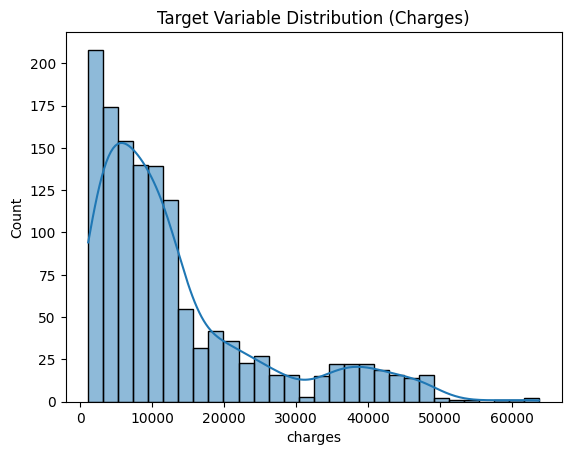

In [31]:
#TARGET DISTRIBUTION

sns.histplot(data['charges'], kde=True)
plt.title('Target Variable Distribution (Charges)')
plt.show()


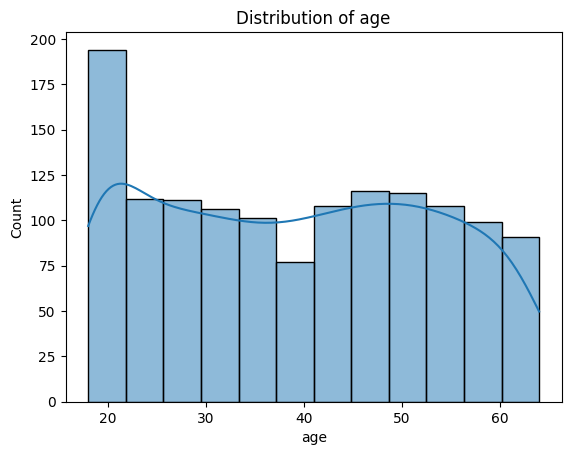

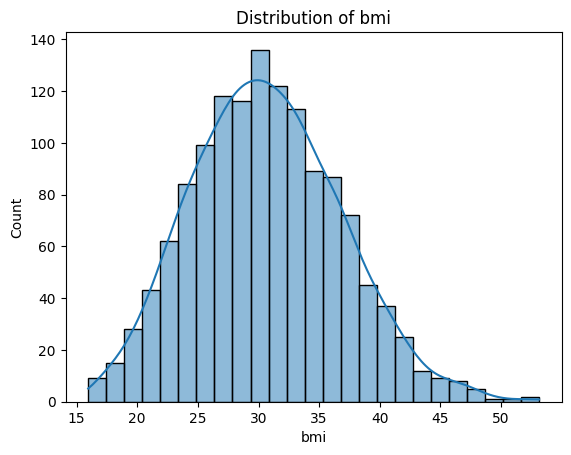

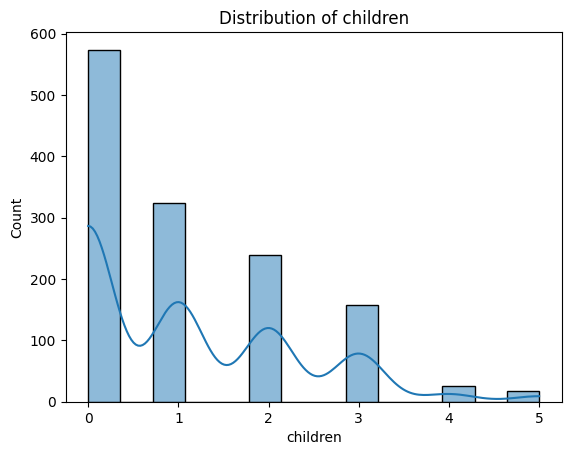

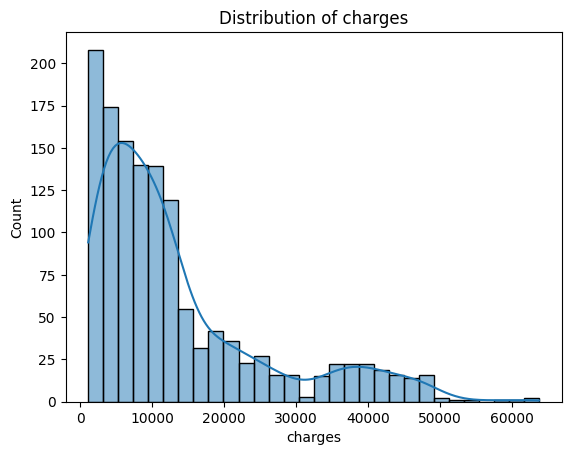

In [32]:
#UNIVARIATE ANALYSIS

for col in data.select_dtypes(include=np.number).columns:
    sns.histplot(data[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()


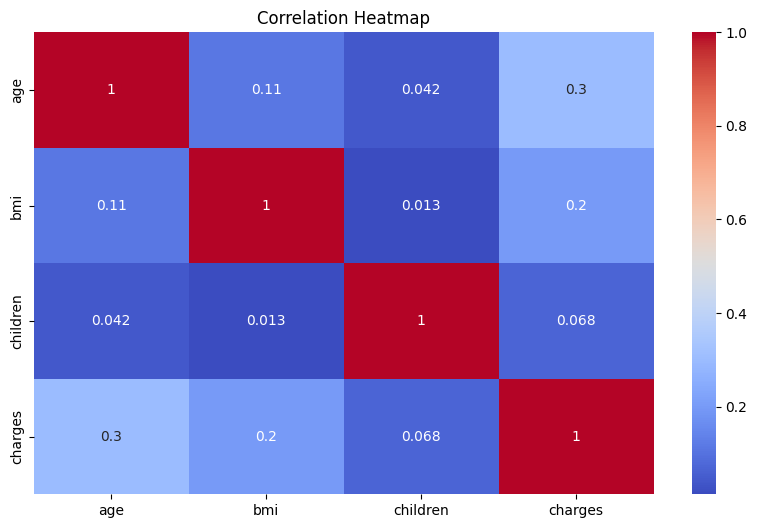

In [33]:
#CORRELATION HEATMAP

plt.figure(figsize=(10,6))
sns.heatmap(data.select_dtypes(include=['number']).corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [34]:
numeric_data = data.select_dtypes(include=np.number)

Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)
IQR = Q3 - Q1

# Outlier detection
outliers = ((numeric_data < (Q1 - 1.5 * IQR)) | (numeric_data > (Q3 + 1.5 * IQR)))
print("Outliers per column:\n", outliers.sum())

Outliers per column:
 age           0
bmi           9
children      0
charges     139
dtype: int64


OULIER DETECTION (VISUAL)

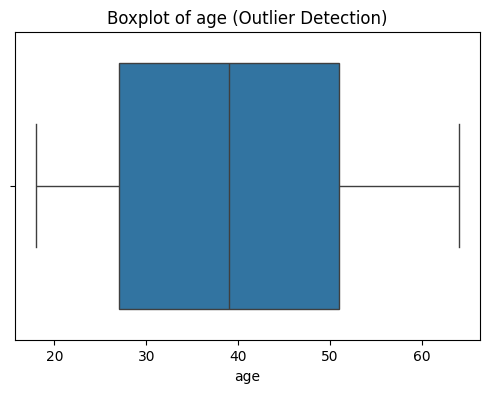

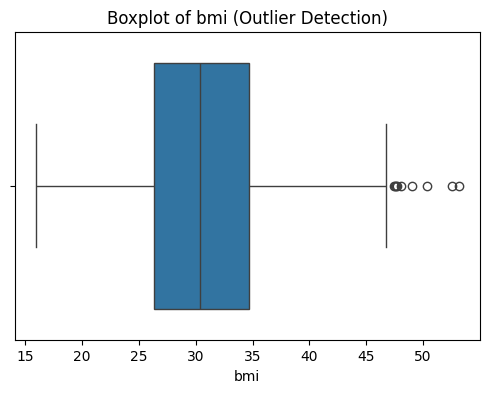

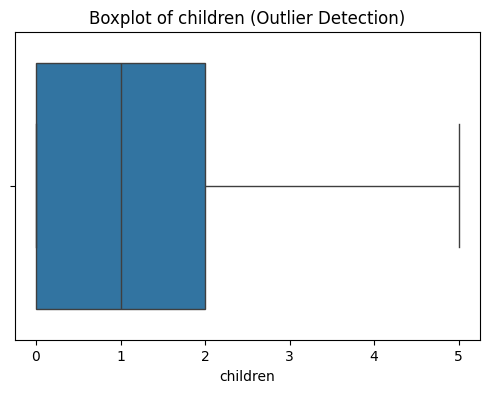

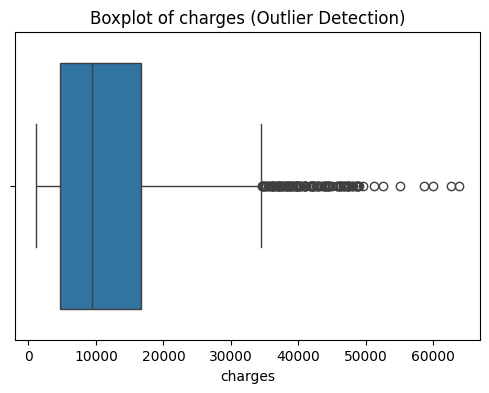

In [35]:
numeric_data = data.select_dtypes(include=np.number)

for col in numeric_data.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=numeric_data[col])
    plt.title(f'Boxplot of {col} (Outlier Detection)')
    plt.show()

# EDA CONCLUSUION

#  Charges are right-skewed hence indicates presence of outliers
#  Age and smoking show strong relationship with charges
#  BMI has moderate influence

# Based on these insights, models like Random Forest and Gradient Boosting are selected as they handle non-linearity, skewness, and outliers effectively.

COVERT CATEGORICAL VARIABLES INTO NUMERIC

In [36]:
X = pd.get_dummies(data.drop('charges', axis=1), drop_first=True)
y = data['charges']


In [37]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Created pipelines for different regression models
# Imputer is used to handle missing values before training the model

In [38]:
models = {
    'Linear Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', LinearRegression())
    ]),

    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeRegressor(random_state=42))
    ]),

    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestRegressor(random_state=42))
    ]),

    'Gradient Boosting': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', GradientBoostingRegressor(random_state=42))
    ])
}


# Trained each model and evaluate it using R2 Score, RMSE, and MAE

In [49]:
results = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    results[name] = {
        'R2 Score': r2,
        'RMSE': rmse,
        'MAE': mae
    }


RESULTS DATAFRAME + VISUALIZATION

Model Performance Comparison:


,R2 Score,RMSE,MAE
Linear Regression,0.783593,5796.284659,4181.194474
Decision Tree,0.726588,6515.129163,3195.110473
Random Forest,0.865103,4576.299916,2550.078471
Gradient Boosting,0.879257,4329.570011,2443.483262


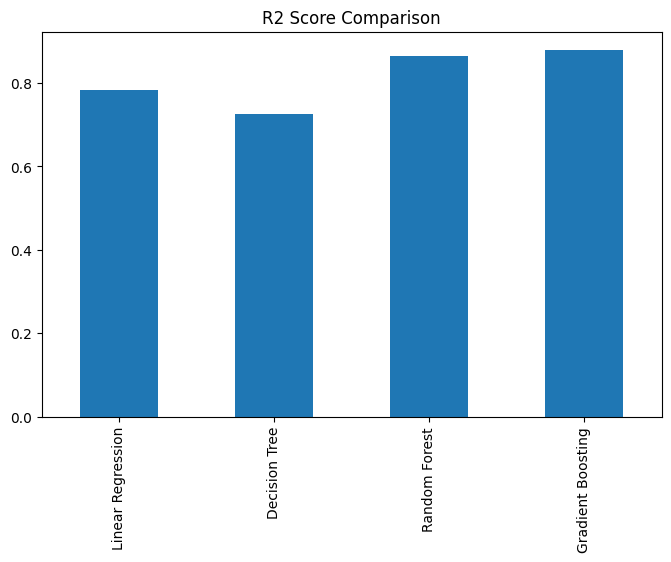

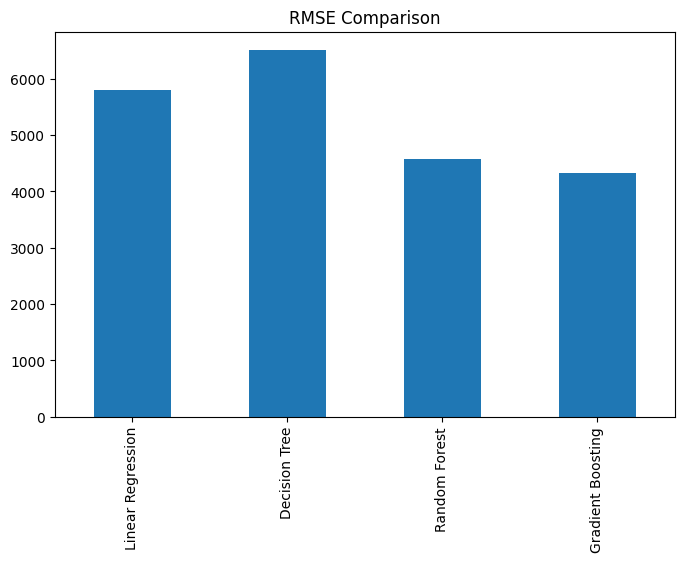

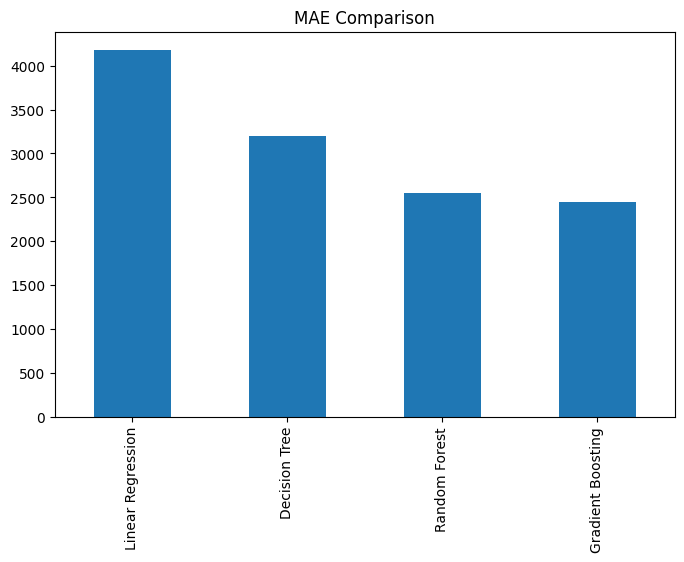

In [53]:
result_data = pd.DataFrame(results).T
print("Model Performance Comparison:")
display(result_data)

# R2 SCORE
result_data['R2 Score'].plot(kind='bar', figsize=(8,5))
plt.title('R2 Score Comparison')
plt.show()

# RMSE
result_data['RMSE'].plot(kind='bar', figsize=(8,5))
plt.title('RMSE Comparison')
plt.show()

# MAE
result_data['MAE'].plot(kind='bar', figsize=(8,5))
plt.title('MAE Comparison')
plt.show()

HYPERPARAMETER TUNING - GRADIENT BOOSTING


# Performed hyperparameter tuning on Gradient Boosting to improve model performance

In [41]:
from sklearn.model_selection import RandomizedSearchCV

gb_pipeline_tuned = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', GradientBoostingRegressor(random_state=42))
])

# Parameter Distribution
param_dist_gb = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'model__max_depth': [3, 4, 5, 6],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__subsample': [0.7, 0.8, 0.9, 1.0]
}

# Randomized Search
search_gb = RandomizedSearchCV(
    gb_pipeline_tuned,
    param_distributions=param_dist_gb,
    n_iter=15,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42
)

# Train
search_gb.fit(X_train, y_train)

# Best Model
best_gb = search_gb.best_estimator_

print("Best Parameters:", search_gb.best_params_)

Best Parameters: {'model__subsample': 0.8, 'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_depth': 4, 'model__learning_rate': 0.05}


EVALUATE TUNED GRADIENT BOOSTING

In [42]:
# Prediction
y_pred_gb = best_gb.predict(X_test)

# Evaluating using R2 Score, RMSE, and MAE
print("Gradient Boosting R2:", r2_score(y_test, y_pred_gb))
print("Gradient Boosting RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_gb)))
print("Gradient Boosting MAE:", mean_absolute_error(y_test, y_pred_gb))

Gradient Boosting R2: 0.8759635497923032
Gradient Boosting RMSE: 4388.223051929727
Gradient Boosting MAE: 2478.182716663835


FEAUTURE IMPORTANCE

Feature importance analysis was conducted to identify the most influential variables affecting insurance charges. This helps interpret the model and understand which factors contribute most to predictions. Key features such as BMI, age, and smoking status were found to have significant impact.

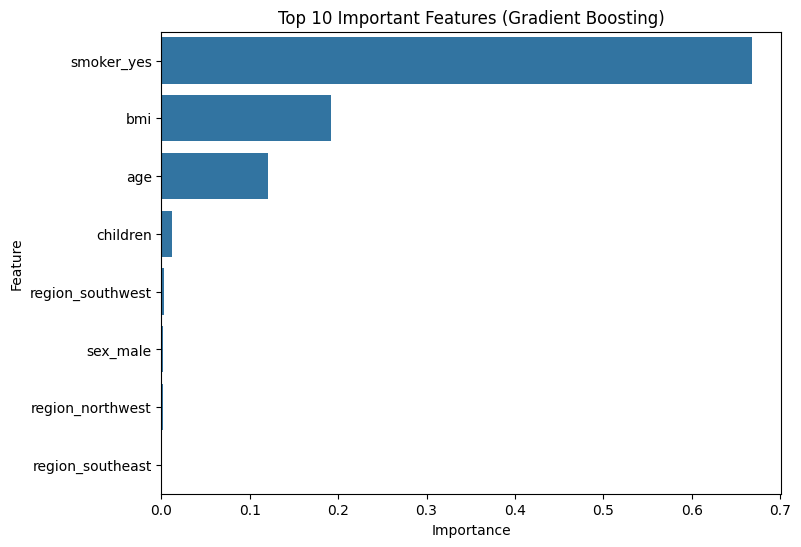

In [43]:
gb_model = best_gb.named_steps['model']

importances = gb_model.feature_importances_
features = X.columns

feat_data_gb = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x='Importance', y='Feature', data=feat_data_gb.head(10))
plt.title('Top 10 Important Features (Gradient Boosting)')
plt.show()

FEATURE IMPORTANCE COMPARISION


In [44]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

tree_pipelines = {
    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeRegressor(random_state=42))
    ]),

    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestRegressor(random_state=42))
    ]),

    'Gradient Boosting': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', GradientBoostingRegressor(random_state=42))
    ])
}

feature_importances = {}

# Decision Tree
dt = tree_pipelines['Decision Tree']
dt.fit(X_train, y_train)
feature_importances['Decision Tree'] = dt.named_steps['model'].feature_importances_

# Random Forest
rf = tree_pipelines['Random Forest']
rf.fit(X_train, y_train)
feature_importances['Random Forest'] = rf.named_steps['model'].feature_importances_

# Gradient Boosting
gb = tree_pipelines['Gradient Boosting']
gb.fit(X_train, y_train)
feature_importances['Gradient Boosting'] = gb.named_steps['model'].feature_importances_
feat_df = pd.DataFrame(feature_importances, index=X.columns)
feat_df = feat_df.sort_values(by='Random Forest', ascending=False)

print(feat_df.head(10))



                  Decision Tree  Random Forest  Gradient Boosting
smoker_yes             0.609529       0.608618           0.676618
bmi                    0.208502       0.216506           0.190540
age                    0.138868       0.134232           0.118372
children               0.017962       0.019413           0.010212
sex_male               0.003275       0.006379           0.000627
region_northwest       0.007834       0.005587           0.001726
region_southeast       0.011058       0.005314           0.000526
region_southwest       0.002972       0.003950           0.001378


# Compared feature importance across Decision Tree, Random Forest and Gradient Boosting models

<Figure size 1000x600 with 0 Axes>

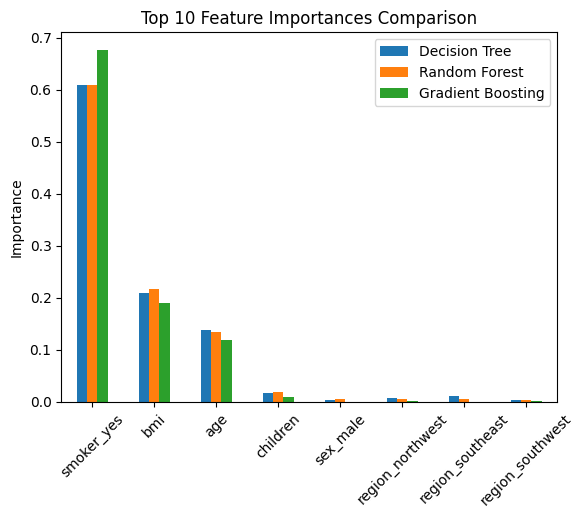

In [45]:
plt.figure(figsize=(10,6))
feat_df.head(10).plot(kind='bar')
plt.title('Top 10 Feature Importances Comparison')
plt.ylabel('Importance')
plt.xticks(rotation=45)
plt.show()

PLOT COMPARISION

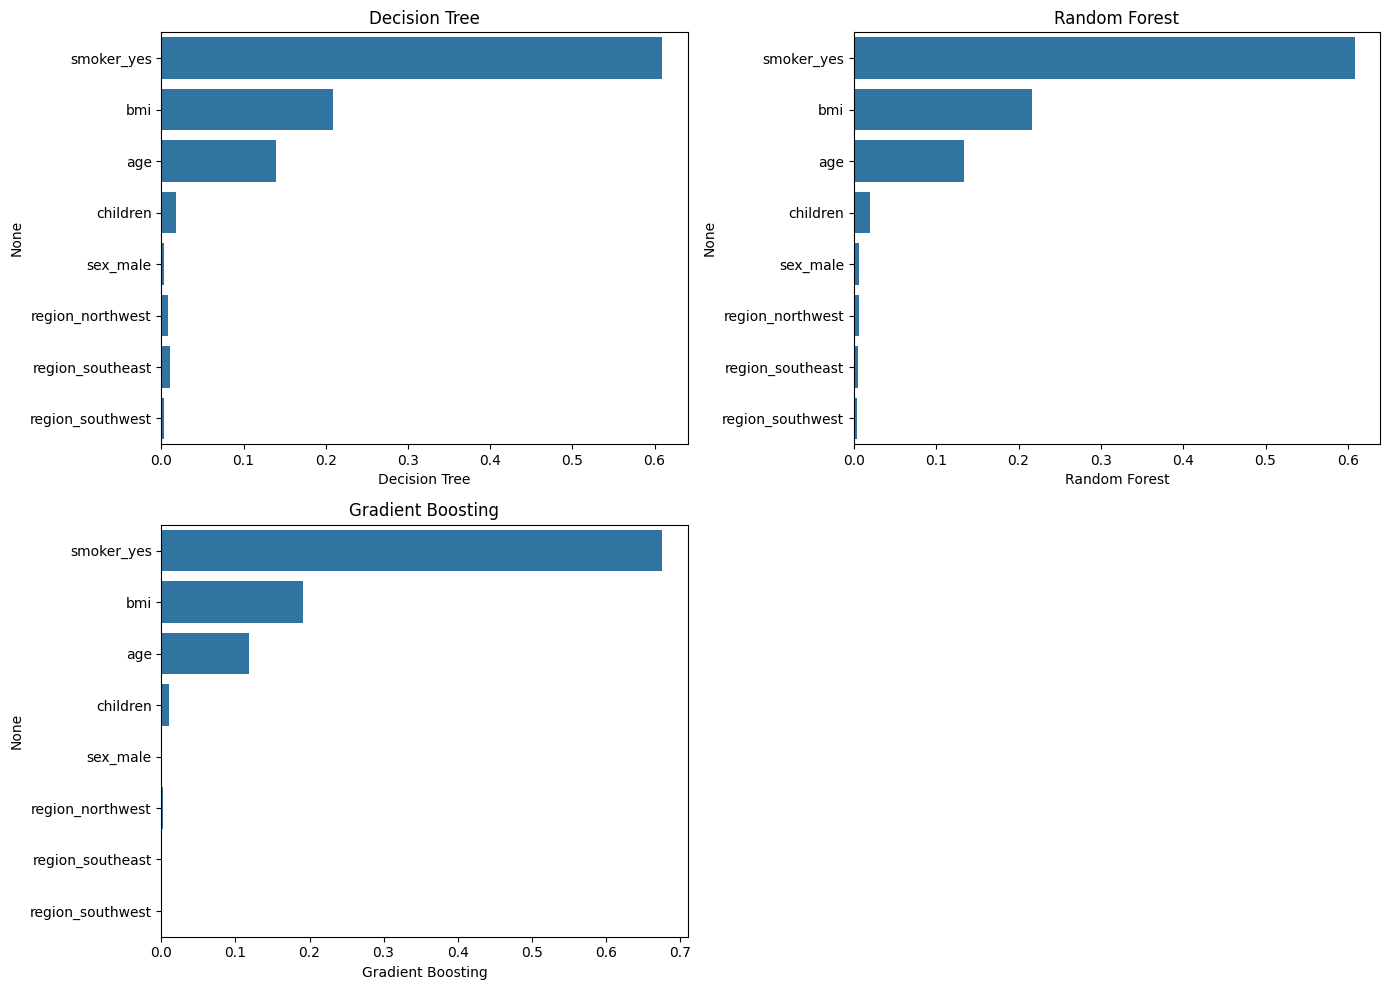

In [54]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

sns.barplot(x=feat_df['Decision Tree'].head(10), y=feat_df.index[:10], ax=axes[0,0])
axes[0,0].set_title('Decision Tree')

sns.barplot(x=feat_df['Random Forest'].head(10), y=feat_df.index[:10], ax=axes[0,1])
axes[0,1].set_title('Random Forest')

sns.barplot(x=feat_df['Gradient Boosting'].head(10), y=feat_df.index[:10], ax=axes[1,0])
axes[1,0].set_title('Gradient Boosting')

fig.delaxes(axes[1,1])

plt.tight_layout()
plt.show()

RESIDUAL ANALYSIS

Residual analysis was performed to evaluate model errors. A well-performing model should produce residuals that are randomly distributed around zero, indicating no systematic bias. This helps verify that the model has captured the underlying patterns in the data effectively.

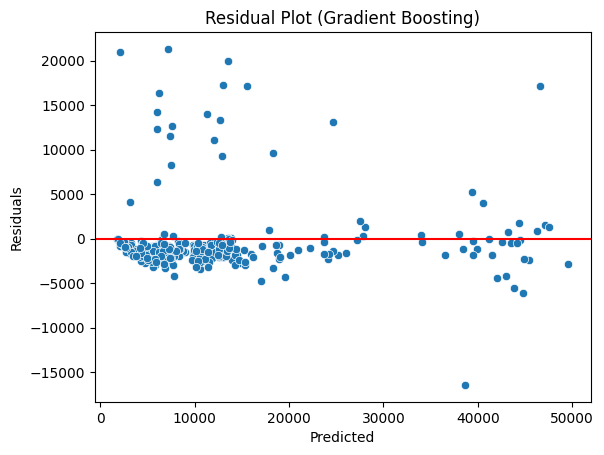

In [47]:
residuals = y_test - y_pred_gb

sns.scatterplot(x=y_pred_gb, y=residuals)
plt.axhline(0, color='red')
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Plot (Gradient Boosting)")
plt.show()

ACTUAL VS PREDICTED

# Compared actual charges with predicted charges to check model performance


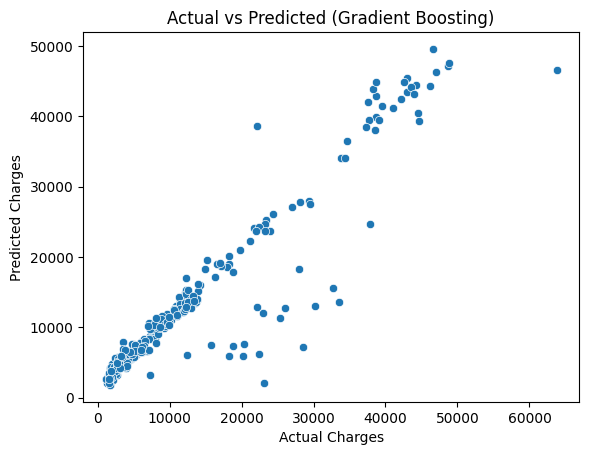

In [48]:
sns.scatterplot(x=y_test, y=y_pred_gb)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted (Gradient Boosting)")
plt.show()

# Project Overview:
# This project aims to predict medical insurance charges based on customer details such as age, BMI, smoking status, sex, and region.
# First, the dataset is loaded and explored using basic EDA techniques to understand the data distribution, relationships, and possible outliers.
# Then, categorical variables are converted into numerical format so that machine learning models can process them.
# After splitting the data into training and testing sets, multiple regression models are trained and compared using R2 Score, RMSE, and MAE.
# Among all models, Gradient Boosting performed best, so hyperparameter tuning was applied using RandomizedSearchCV to improve its performance further.
# Finally, the tuned model is evaluated using Actual vs Predicted plot, Residual plot, and Feature Importance analysis to understand both performance and the impact of different features.

# Conclusion:
# Gradient Boosting achieved the best performance among all models and after tuning it provided accurate predictions for insurance charges.